# System-One Multi: one GLiNER2 model for decisions, entities and relations

> gliner2.5-multi-v1 trained further on gold labels from public datasets: one model that makes decisions of every kind, finds entities of every type, and relates them, entity to entity, event to event (what causes what, what must happen first, what comes before) and statement to statement (what implies or rules out what). The data built and the models scored on Kaggle, the training on Modal.

- skip_exec: true
- skip_showdoc: true

A GLiNER2 model reads a text together with a *schema*, the things you ask it to find, and answers all of it in one pass: entities of the types you name, relations between them, records with fields, and decisions among labels you give. Fastino publishes [gliner2.5-multi-v1](https://huggingface.co/fastino/gliner2.5-multi-v1), which does all four, and [GLiNER2.5-multi-Decide](https://huggingface.co/fastino/GLiNER2.5-multi-Decide), the same model fine-tuned to decide. Both are *boundary* models: they find a span by predicting where it starts and where it ends, so a span can be a word or a whole clause.

This notebook starts from gliner2.5-multi-v1 for that architecture (the English GLiNER2.5-Decide is not a boundary model), and trains it on gold labels from many public datasets at once, so that one model gets better at three things:

- **Decisions** of every kind: picking an option, rating on a scale, answering yes or no.
- **Entities** of any type you name.
- **Relations** of any kind: between entities ("country", "manufacturer"), between events ("causes", "is a precondition of", "happens before", "has subevent"), and between whole statements ("implies", "rules out").

The data and the tests are in English. One use in view is prediction markets. A market is a question such as "Will Bitcoin close above $90,000 on June 30?", and markets depend on each other: one resolving yes can force another to resolve yes, or make it impossible. [Saguillo et al. (2025)](https://arxiv.org/abs/2508.03474) found such pairs on Polymarket by asking an LLM about every pair of markets, 46,360 pairs for the 305 politics markets of one election day. A model that marks *implies*, *rules out* and *is a precondition of* between the questions of a list builds the same graph in a few hundred passes.

```{mermaid}
flowchart LR
  D["public datasets<br/>decisions, entities,<br/>relations, events, statements"] --> R["gold rows<br/>(sysone.multitask readers)"]
  G["a market generator<br/>exact labels"] --> R
  X["market questions<br/>Paleka et al., Kalshi,<br/>Polymarket, Manifold"] --> R
  R --> K["Kaggle: training records,<br/>test suites, the starting line"]
  K --> M["Modal: training<br/>every weight, or an adapter"]
  M --> S["Kaggle: scores and<br/>dependency graphs"]
```

The steps, and where each runs:

1. **A first try** (from an earlier version of this notebook): an adapter trained to copy the two models, and why it was not enough.
2. **The training mix** (a Kaggle job): 153,791 training records and 18 test suites from 16 sources, each row with its gold.
3. **The starting line** (the same job): gliner2.5-multi-v1 and GLiNER2.5-multi-Decide on every suite.
4. **Round 1** (Modal GPUs, then a Kaggle job): three ways to train (every weight or an adapter; the heads' losses balanced or summed), scored on every suite, and a sweep of thresholds.
5. **Round 2**: the mix and the loss changed for what round 1 missed, an adapter trained for two epochs.
6. **Dependency graphs** over many market questions.
7. **Round 3** (a Kaggle CPU job, then Modal): market questions people wrote, and the exchanges' own rules, for dependencies between markets; the speed, and the published adapter.

::: {.callout-tip title="Jargon"}
- **Gold label**: the answer a dataset's annotators gave; training teaches the model to give it too.
- **Span**: a stretch of the text. **Trigger**: the word that names an event ("attacked", "flood").
- **F1**: the harmonic mean of precision (the share of what the model found that is right) and recall (the share of what is there that it found). *Strict* F1 counts a span right only with exactly the gold's words; *relaxed* F1 also when one contains the other.
- **Full fine-tune** and **adapter**: training every weight of the model, or small added matrices beside its layers (LoRA) while its own weights stay as they were.
- **Confidence interval**: the range a score would likely fall in on another sample of the same kind of rows; here from resampling the test rows 1,000 times.
:::

::: {.callout-note title="Running this notebook"}
The test suite skips this notebook (`skip_exec`). It runs on a laptop and sends the heavy steps elsewhere as [jobs](../40_cloud.ipynb): building the data and scoring to a Kaggle T4 (free, within Kaggle's weekly GPU quota), the training to Modal GPUs (paid by the second). The cells that start jobs are marked `#| eval: false`; the rest read the outputs of the runs shown here, by their job ids, so running it again shows the same results without starting anything. Starting the jobs again needs `sysone login kaggle` and `modal setup`, and the `gliner` and `modal` extras.
:::

In [ ]:
import gzip, json, re, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from transformers.utils import logging as hf_logging
from sysone.cloud import remote, get_job

warnings.filterwarnings("ignore"); hf_logging.set_verbosity_error()
set_matplotlib_formats("png"); plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                                                    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
JOBS = Path("system-one-multi")            # the job scripts, beside this notebook
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]       # categorical, in this order (checked for colour-blind separation)
def read_jsonl(p): return [json.loads(l) for l in open(p)]

## A first try: copying two models

The first version of this notebook took another road. GLiNER2.5-multi-Decide decides better than its base and has lost most of its extraction; it built one LoRA adapter over the base and trained it to copy both: Decide's scores on decision rows, the base's findings on extraction rows. That adapter is the private `sgaseretto/system-one-multi`. The [distillation notebook](../32_gliner_distill.ipynb) holds its pieces; its scores:

In [ ]:
OLD = {"prep": "kaggle-20261029-233719-7b6a", "eval": "kaggle-20261030-010147-5746"}   # the first version's Kaggle jobs
old = {}
for j in OLD.values(): old |= json.loads((Path(get_job(j).fetch()) / "export" / "scores.json").read_text())
cols = {"fast-decisions": ("fast-decisions", "accuracy"), "MASSIVE, 6 languages": ("massive", "accuracy"), "typed decisions": ("typed-decisions", "accuracy"),
        "MultiCoNER entities F1": ("multiconer", "entities_f1_gold"), "CrossNER entities F1": ("crossner", "entities_f1_gold")}
who = {"gliner2.5-multi-v1 (base)": "gliner2.5-multi-v1", "GLiNER2.5-multi-Decide": "GLiNER2.5-multi-Decide", "system-one-multi-r64-equal": "the distilled adapter"}
pd.DataFrame({who[n]: {c: old[n][s][k] for c, (s, k) in cols.items()} for n in who}).T.style.format("{:.3f}")

,fast-decisions,"MASSIVE, 6 languages",typed decisions,MultiCoNER entities F1,CrossNER entities F1
gliner2.5-multi-v1,0.520,0.497,0.388,0.290,0.588
GLiNER2.5-multi-Decide,0.626,0.563,0.461,0.000,0.190
the distilled adapter,0.592,0.580,0.476,0.308,0.588


It got the extraction back and kept most of the decisions, but three things held it back:

- **Training traded one skill for the other.** The adapter started from the change between the two models and agreed with Decide on 91% of held-out decisions; training it to extract again brought that down to 81%. The decision loss is tiny next to GLiNER2's summed extraction losses, so extraction steered nearly every step.
- **A copy cannot pass its teachers.** Its decisions were at best Decide's, its entities the base's, mistakes included.
- **Nothing teaches what neither model knows.** Neither finds a single relation between events or between statements (both score 0 below), so there was nothing to copy.

So this version trains on gold labels: what the datasets' annotators wrote, for every skill, the relations included.

## The training mix

Every source becomes rows of one shape: a text, what to find in it, and the gold, with each gold span given by its characters in the text. The readers are in [GLiNER multitask](../33_gliner_multitask.ipynb):

| skill | sources | what a row asks |
|---|---|---|
| decisions | [tasksource-jev-typed-decisions](https://huggingface.co/datasets/tasksource/tasksource-jev-typed-decisions) (826 tasks), [typed-decisions](https://huggingface.co/datasets/LocalLLaMA/typed-decisions), [MASSIVE](https://huggingface.co/datasets/mteb/amazon_massive_intent) | the questions about one text: pick an option, rate on a scale, answer yes or no; annotator disagreement kept as soft targets |
| entities and spans | jev's extraction config (named entities, claims, phrases, question answering), [MultiCoNER](https://huggingface.co/datasets/MultiCoNER/multiconer_v2), [NuNER](https://huggingface.co/datasets/numind/NuNER) | the types a text has, and some it lacks |
| relations between entities | [RED^FM and SRED^FM](https://huggingface.co/datasets/Babelscape/REDFM), [Re-DocRED](https://huggingface.co/datasets/tonytan48/Re-DocRED) | Wikidata relations ("country", "author") between the entities of a passage |
| events | [MAVEN-ERE](https://github.com/THU-KEG/MAVEN-ERE), MAVEN's event types, [MAVEN-Arg](https://huggingface.co/datasets/mneb/maven-arg), the [Causal News Corpus](https://huggingface.co/datasets/thagen/CNCv2) | events and how they relate (causes, is a precondition of, has subevent, six relations in time, the same event); events with their arguments as records; causes and effects between clauses |
| statements | [MultiNLI](https://huggingface.co/datasets/nyu-mll/multi_nli), [e-CARE](https://huggingface.co/datasets/12ml/e-CARE), generated markets | lists of statements, related by implies, rules out, causes and is a precondition of |

The job builds the test suites first, from each source's own test or validation split, then the training rows, and drops every training row whose text is a test row's or nearly (MinHash, Jaccard ≥ 0.6). Each training record then goes through GLiNER2's own processor, as training will collate it, and one it refuses is left out:

In [ ]:
#| eval: false
prep_job = remote(JOBS / "gold_prepare.py", on="kaggle", hw="t4", packages=["gliner2==2.1.0"], max_hours=4, checkpoints=False, name="gold-prepare")
prep_job.wait()

The job takes about 25 minutes, and its output is worth keeping, so it is stored twice, privately, with a card `gold_data_card` writes from it ([GLiNER multitask](../33_gliner_multitask.ipynb#keeping-the-data)): as a Hub dataset, which the training jobs on Modal read as `hf:sgaseretto/system-one-multi-gold`, and as a Kaggle dataset, which the scoring jobs mount as `kaggle:sgaseretto/system-one-multi-gold`. Neither has to build it again, nor wait for it to travel from this laptop.

In [ ]:
#| eval: false
from sysone.hub import push_data
from sysone.kaggle import kaggle_dataset
from sysone.multitask import gold_data_card
GOLD = "sgaseretto/system-one-multi-gold"
built = Path(prep_job.fetch()) / "export"
gold_data_card(built, GOLD, title="System-One Multi gold mix", built_by="the `gold_prepare.py` job of sysone's System-One Multi tutorial")
push_data(built, GOLD, private=True)
kaggle_dataset(built, GOLD)                                  # waits until Kaggle has processed it

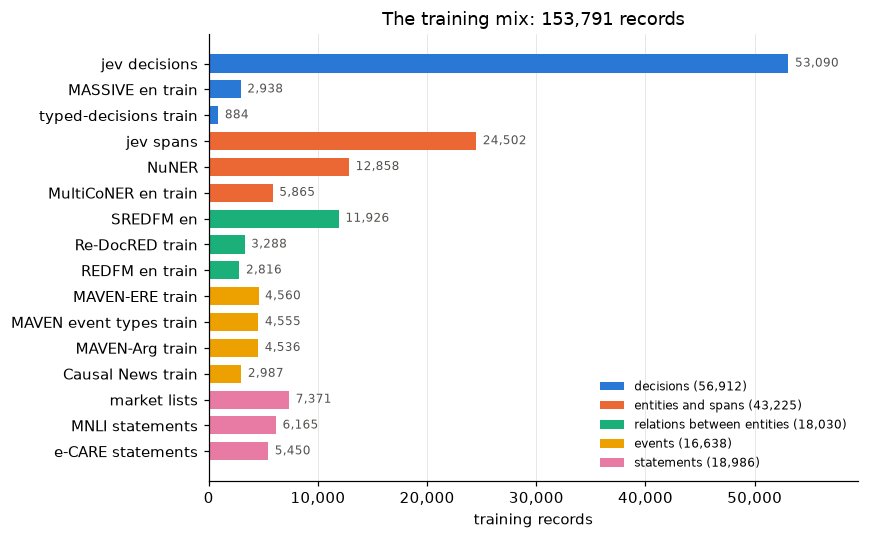

In [ ]:
PREP = "gold-prepare"                                        # the Kaggle job that built the data and scored the two models
prep = Path(get_job(PREP).fetch()) / "export"
data = json.loads((prep / "data.json").read_text())
SKILL = {"jev decisions": "decisions", "typed-decisions train": "decisions", "MASSIVE en train": "decisions",
         "jev spans": "entities and spans", "MultiCoNER en train": "entities and spans", "NuNER": "entities and spans",
         "REDFM en train": "relations between entities", "SREDFM en": "relations between entities", "Re-DocRED train": "relations between entities",
         "MAVEN-ERE train": "events", "MAVEN event types train": "events", "MAVEN-Arg train": "events", "Causal News train": "events",
         "MNLI statements": "statements", "e-CARE statements": "statements", "market lists": "statements"}
mix = pd.DataFrame([{"dataset": d, "skill": SKILL[d], "records": k} for d, k in data["train"].items()])
mix["skill"] = pd.Categorical(mix.skill, list(dict.fromkeys(SKILL.values())))
mix = mix.sort_values(["skill", "records"], ascending=[True, False]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 5))
y = len(mix) - 1 - mix.index.to_numpy()                       # the first row at the top
for (skill, g), c in zip(mix.groupby("skill", observed=True), COLORS):
    ax.barh(y[g.index], g.records, height=0.7, color=c, label=f"{skill} ({g.records.sum():,})")
for yy, k in zip(y, mix.records): ax.text(k + 600, yy, f"{k:,}", va="center", fontsize=8, color="#52514e")
ax.set(yticks=y, yticklabels=mix.dataset, xlabel="training records", title=f"The training mix: {mix.records.sum():,} records")
ax.grid(axis="y", visible=False); ax.legend(fontsize=8, loc="lower right", frameon=False); ax.set_xlim(0, mix.records.max() * 1.12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout()

Decisions are about a third of the mix, though jev alone has a million rows: the job takes at most 120 requests from each of its 826 tasks, so that no task, and no skill, drowns the rest. Here is one training record from each of three sources, as GLiNER2 reads it: the text, then what to find (`output`), each gold span with its characters:

In [ ]:
train = [json.loads(l) for l in gzip.open(prep / "train.jsonl.gz", "rt")]
def show(e, chars=700):
    o = json.loads(json.dumps(e["output"]))
    for r in o.get("relations", []):
        for name, x in r.items(): r[name] = {k: (v["text"] if isinstance(v, dict) else v) for k, v in x.items()}
    for t, xs in (o.get("entities") or {}).items(): o["entities"][t] = [x["text"] if isinstance(x, dict) else x for x in xs]
    print(f"--- {e['dataset']}: {e['input'][:chars]}" + ("…" if len(e["input"]) > chars else ""))
    print(json.dumps({k: v for k, v in o.items() if not k.endswith("descriptions")}, ensure_ascii=False)[:chars])
for d in ("market lists", "MAVEN-ERE train", "jev decisions"):
    show(next(e for e in train if e["dataset"] == d and (d != "MAVEN-ERE train" or len(e["input"]) < 700)))

--- market lists: - Will PSG win the Champions League?
- Will PSG reach the final of the Champions League?
{"relations": [{"implies": {"head": "Will PSG win the Champions League", "tail": "Will PSG reach the final of the Champions League"}}, {"rules out": {"head": "", "tail": ""}}, {"is a precondition of": {"head": "Will PSG reach the final of the Champions League", "tail": "Will PSG win the Champions League"}}]}
--- MAVEN-ERE train: In a statement on the Al-Hanein jihadi website, the Islamic State of Iraq (ISI) said Tuesday's attacks were to avenge "insults" against Aisha, the wife of Islam's Prophet Mohammed.
{"entities": {"event": ["attacks", "statement", "avenge", "said", "insults"]}, "relations": [{"causes": {"head": "insults", "tail": "avenge"}}, {"is a precondition of": {"head": "", "tail": ""}}, {"has subevent": {"head": "", "tail": ""}}, {"happens before": {"head": "insults", "tail": "avenge"}}, {"overlaps in time with": {"head": "", "tail": ""}}, {"contains in time": {"head":

A relation asked with an empty head and tail is a negative: the text has none of it, and the model learns to find none. In the market list, neither question rules out the other; in the MAVEN-ERE passage, no event is a subevent of another. Every relation type, entity type and record a row asks for and its gold lacks teaches the same thing.

## The starting line

The same job had both models answer the 8,956 test rows. Each suite gets one headline score: accuracy for decisions, and strict F1 for the entities, records or relations it asks for:

In [ ]:
HEADLINE = [("decisions", "fast-decisions", "accuracy"), ("decisions", "typed-decisions", "accuracy"), ("decisions", "massive", "accuracy"),
            ("decisions", "jev decisions", "accuracy"), ("entities", "multiconer", "entities_f1"), ("entities", "crossner", "entities_f1"),
            ("entities", "jev entities", "entities_f1"), ("entities", "jev records", "records_f1"), ("entity relations", "redfm", "relations_f1"),
            ("entity relations", "re-docred", "relations_f1"), ("events", "maven event types", "entities_f1"), ("events", "maven-ere", "relations_f1"),
            ("events", "maven-arg", "records_f1"), ("events", "causal news", "relations_f1"), ("statements", "mnli statements", "relations_f1"),
            ("statements", "e-care statements", "relations_f1"), ("statements", "markets", "relations_f1"), ("statements", "markets (ranges)", "relations_f1")]
def headline(scores:dict) -> pd.DataFrame:
    "One row per model, one column per suite: its headline score"
    cols = pd.MultiIndex.from_tuples([(g, s) for g, s, _ in HEADLINE])
    return pd.DataFrame([[scores[m].get(s, {}).get(k, np.nan) for _, s, k in HEADLINE] for m in scores], index=list(scores), columns=cols)
start = json.loads((prep / "scores.json").read_text())
headline(start).T.style.format("{:.3f}").background_gradient(cmap="Blues", axis=1, vmin=0, vmax=1)

- **Decide decides better, but not everywhere.** It is right more often on fast-decisions (0.626 against 0.520), typed decisions (0.461 against 0.388) and MASSIVE (0.613 against 0.537), and no better on jev's 2,237 decisions from hundreds of tasks (0.440 against 0.446).
- **Its extraction is gone.** It finds no MultiCoNER entity that is right, gets 0.07 F1 on RED^FM's entities against the base's 0.50, and finds almost no relation.
- **The base relates entities a little, and nothing else.** It gets 0.18 F1 on RED^FM's relations and 0.09 on Re-DocRED's. Between events (MAVEN-ERE, the Causal News Corpus) and between statements (MultiNLI, e-CARE, markets), neither model finds a single relation: whatever the trained model does there, it learned here.

## Round 1: training on Modal

`GlinerLearner` ([GLiNER multitask](../33_gliner_multitask.ipynb#training-on-gold)) trains on the records for one epoch: 152,557 of them (1,234 longer than 384 words, which GLiNER2 would cut, are left out), in batches of up to 16 records and 4,096 padded tokens, 11,165 steps. Three runs, on Modal L40S GPUs with 4 cores and 16 GB each, try two choices:

- **Every weight, or an adapter.** A full fine-tune trains all 287 million numbers, the encoder at 10⁻⁵ and the heads at 10⁻⁴ (GLiNER2's own trainer uses 10⁻⁵ and 5·10⁻⁴, for heads trained from scratch; these are trained already). The adapter trains 20.5 million: rank-64 LoRA matrices on the encoder's 72 linear layers at 2·10⁻⁴, and the heads, whole, at 10⁻⁴.
- **How the losses add up.** GLiNER2's forward pass gives a loss per head: the decisions' is below one, the relations' about half, the spans' in the hundreds or thousands (it sums over every query and candidate). Summed as GLiNER2 sums them, the spans steer every step. *Balanced*, each loss is first divided by its own running average, so the three weigh alike.

In [ ]:
#| eval: false
modal = dict(on="modal", hw="l40s", data={"data": "hf:sgaseretto/system-one-multi-gold"}, packages=["gliner2==2.1.0"], max_hours=1.5, cpu=4, memory_gb=16,
             budget=20)                             # the stored mix, read from the Hub by the job itself (the runs shown shipped
                                                    # the same files from this laptop, before the mix was stored)
runs = {"full, balanced": {"MODE": "full", "BALANCE": "1", "LR": "1e-5", "HEAD_LR": "1e-4"},
        "adapter, balanced": {"MODE": "adapter", "RANK": "64", "BALANCE": "1", "LORA_LR": "2e-4", "HEAD_LR": "1e-4"},
        "full, summed": {"MODE": "full", "BALANCE": "0", "LR": "1e-5", "HEAD_LR": "1e-4"}}
names = {"full, balanced": "multi-full-balanced", "adapter, balanced": "multi-adapter-balanced", "full, summed": "multi-full-sum"}
jobs = {r: remote(JOBS / "gold_train.py", env=env | {"NAME": f"system-one-{names[r]}"}, name=f"gold-{names[r]}", **modal) for r, env in runs.items()}
for j in jobs.values(): j.wait()

`budget=20` makes sysone refuse a job that could take the month's Modal usage past $20. The three runs took 33 to 43 minutes each, 29 to 36 of them training (0.16 to 0.17 seconds a step for a full fine-tune, 0.20 for the adapter) and the rest loading the data and the model and validating, and cost about $5.40 together ($2.90 an hour for an L40S with its cores and memory).

The evaluation job below keeps a copy of each run's training record, so its log can be read without downloading the model:

In [ ]:
EVAL = "gold-evaluate-2"                                     # the Kaggle job that scored the trained models
ev = Path(get_job(EVAL).fetch()) / "export"
RUNS = {"full, balanced": "system-one-multi-full-balanced", "adapter, balanced": "system-one-multi-adapter-balanced", "full, summed": "system-one-multi-full-sum"}
recs = {r: json.loads((ev / f"training-{n}.json").read_text()) for r, n in RUNS.items()}
HEADS = ["decision", "relation", "span"]
pd.DataFrame({r: {"trainable numbers": f"{x['training']['trainable']:,}", "steps": x["training"]["steps"],
                  "training minutes": round(x["training"]["seconds"] / 60, 1)} |
                 {f"{h} loss, before → after": f"{x['before_training'][f'valid_{h}']:.3f} → {x['training']['log'][-1][f'valid_{h}']:.3f}" for h in HEADS}
              for r, x in recs.items()}).T

,trainable numbers,steps,training minutes,"decision loss, before → after","relation loss, before → after","span loss, before → after"
"full, balanced","287,355,159",11165,31.6,0.600 → 0.426,0.439 → 0.302,2279.327 → 579.869
"adapter, balanced","20,518,167",11165,36.4,0.600 → 0.434,0.439 → 0.366,2279.327 → 528.947
"full, summed","287,355,159",11165,28.8,0.600 → 0.488,0.439 → 0.425,2279.327 → 523.428


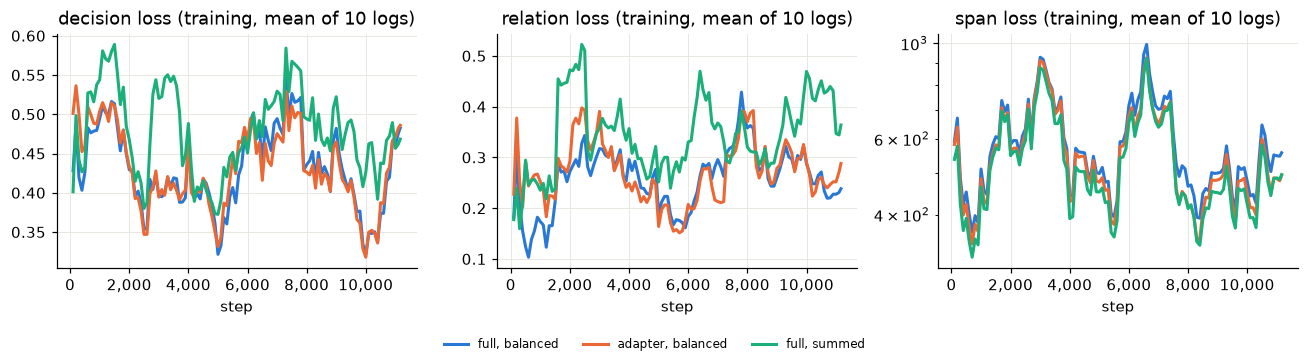

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for (r, x), c in zip(recs.items(), COLORS[:3]):
    log = pd.DataFrame([e for e in x["training"]["log"] if "loss" in e])
    for ax, h in zip(axes, HEADS):
        ax.plot(log.step, log[h].rolling(10, min_periods=1).mean(), color=c, lw=2, label=r)
for ax, h in zip(axes, HEADS):
    ax.set(title=f"{h} loss (training, mean of 10 logs)", xlabel="step"); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[2].set_yscale("log")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))

Balancing pays off where it should. On the 800 validation records, the balanced full fine-tune brings the decision loss from 0.600 to 0.426 and the relation loss from 0.439 to 0.302; summed, the same model gets the decisions only to 0.488 and the relations to 0.425, nearly where they started, while its span loss ends a little lower (523 against 580). The adapter lands between the two, closer to the balanced full fine-tune. The training losses swing with what each batch holds, the span loss most (between a few hundred and a few thousand from one log to the next), which is why they are shown as moving averages.

## Round 1: scores

The trained models answer the same 8,956 test rows on a Kaggle T4. The full fine-tunes travel to Kaggle as private datasets of 1.1 GB each, the adapter as one of 82 MB; the test rows come from the stored mix:

In [ ]:
#| eval: false
models = {"model": "kaggle:sgaseretto/sysone-system-one-multi-full-balanced-8a02c9", "model_2": "kaggle:sgaseretto/sysone-system-one-multi-adapter-balanced-746f2d",
          "model_3": "kaggle:sgaseretto/sysone-system-one-multi-full-sum-126c4b"}       # the three runs' exports, uploaded once
eval_job = remote(JOBS / "gold_evaluate.py", on="kaggle", hw="t4", packages=["gliner2==2.1.0"], max_hours=4, checkpoints=False,
                  data={"eval": "kaggle:sgaseretto/system-one-multi-gold"} | models, name="gold-evaluate-2")
eval_job.wait()

In [ ]:
NAMES = {"gliner2.5-multi-v1 (base)": "gliner2.5-multi-v1", "GLiNER2.5-multi-Decide": "GLiNER2.5-multi-Decide",
         "system-one-multi-full-balanced": "full, balanced", "system-one-multi-adapter-balanced": "adapter, balanced", "system-one-multi-full-sum": "full, summed"}
scores = {NAMES[k]: v for k, v in (start | json.loads((ev / "scores.json").read_text())).items()}
headline(scores).T.style.format("{:.3f}").background_gradient(cmap="Blues", axis=1, vmin=0, vmax=1)

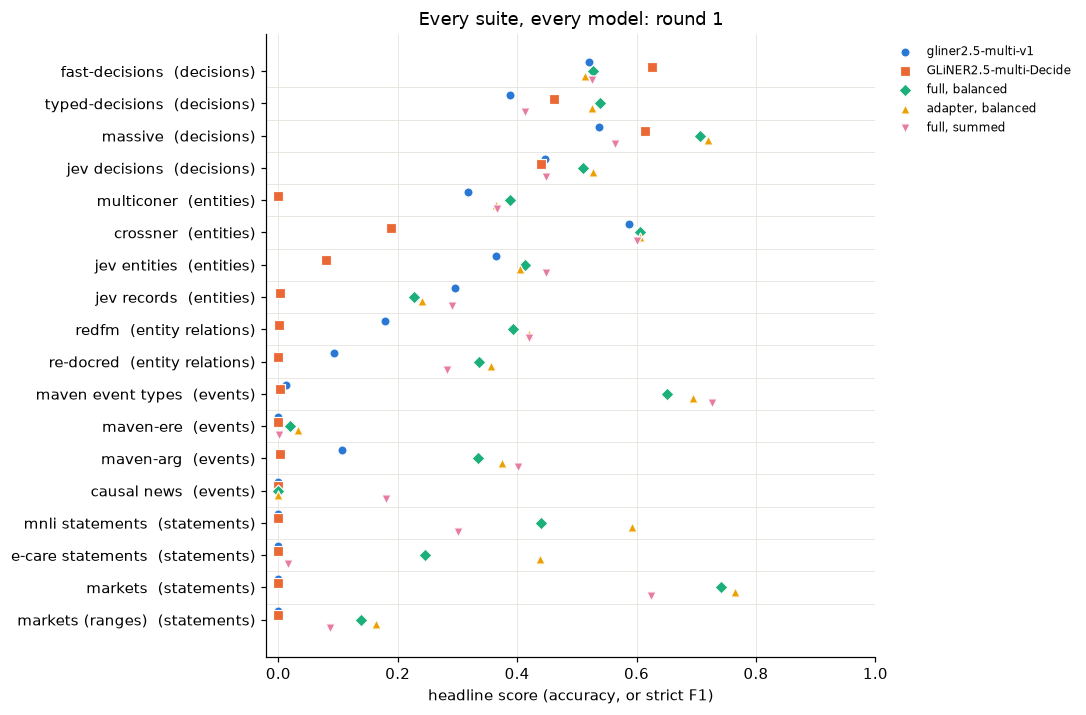

In [ ]:
def dots(scores:dict, title:str):
    "Each suite's headline score, one dot per model"
    t = headline(scores); suites = [f"{s}  ({g})" for g, s in t.columns]
    fig, ax = plt.subplots(figsize=(10, 6.6))
    y = np.arange(len(suites))[::-1]
    shift = np.linspace(0.27, -0.27, len(t))                     # each model a little apart, so equal scores do not hide one another
    for (name, r), c, mk, dy in zip(t.iterrows(), COLORS, "osD^v", shift):
        ax.scatter(r.values, y + dy, s=36, color=c, marker=mk, label=name, zorder=3, edgecolor="#fcfcfb", linewidth=0.8)
    ax.set(yticks=y, yticklabels=suites, xlim=(-0.02, 1.0), xlabel="headline score (accuracy, or strict F1)", title=title)
    for yy in y[:-1]: ax.axhline(yy - 0.5, color="#e6e5e0", lw=0.6, zorder=0)
    ax.grid(axis="y", visible=False); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    plt.tight_layout()
dots(scores, "Every suite, every model: round 1")

Read against the 95% intervals in the scores (a decision suite of 2,000 rows is good to about ±2 points, one of 300 to ±5, an F1 over a few hundred rows to ±2 to ±5):

- **Decisions improve where the training had their kind.** Every trained model passes the base on typed decisions, MASSIVE and jev's decisions, and the balanced ones pass Decide too: the adapter is right on 72% of MASSIVE (Decide 61%, the base 54%) and 53% of jev's decisions (both 44 to 45%). On fast-decisions nothing moves: 51 to 53%, the base's 52%, Decide's 63%. Its operational questions (routing a ticket, triaging an email, handing a conversation to a person) are a kind of decision the mix barely has.
- **Entities stay, and improve.** MultiCoNER rises from 0.32 to 0.37 to 0.39, CrossNER holds at 0.60, and the entities of RED^FM and Re-DocRED rise from 0.50 and 0.66 to about 0.70 and 0.80.
- **Relations between entities double or more.** RED^FM's from 0.18 to 0.39 to 0.42, Re-DocRED's from 0.09 to 0.28 to 0.36.
- **Events: found, not yet related.** From almost nothing, the models find MAVEN's events by type (0.65 to 0.73) and fill their arguments (0.33 to 0.40). But between events they find almost nothing (MAVEN-ERE, 0.02 to 0.03): what they report is right about half the time, and they find one relation in 60 to 100. And the clauses of the Causal News Corpus, causes and effects as whole clauses, only the summed run learned to mark (0.18; 0.35 when a clause one word off counts).
- **Statements: learned from nothing.** Implies and rules out between MultiNLI's statements reach 0.59 with the balanced adapter, causes between e-CARE's 0.44, and the relations between market questions 0.77. A kind of market never seen in training, ranges, stays low (0.16).
- **Balancing is a trade.** Divided by its running average, the span loss weighs no more than the others; the balanced runs decide better and relate statements far better, and mark long spans worse: the summed run is the only one to learn the Causal News clauses, and the best of the three at jev's records (0.29, the base's 0.30).

The trained models are also cautious. At GLiNER2's default threshold of 0.5 they find little of what is there, and much of what they find is right: on MAVEN-ERE, half of their relations are right and they find 1 in 60 to 100. A sweep over lower thresholds on the same rows says how much of that is the threshold:

In [ ]:
#| eval: false
sweep_job = remote(JOBS / "gold_thresholds.py", on="kaggle", hw="t4", packages=["gliner2==2.1.0"], max_hours=3, checkpoints=False,
                   data={"eval": "kaggle:sgaseretto/system-one-multi-gold"} | models, name="gold-thresholds")
sweep_job.wait()

In [ ]:
SWEEP = "gold-thresholds"                                    # the Kaggle job that swept the thresholds
sweep = json.loads((Path(get_job(SWEEP).fetch()) / "export" / "thresholds.json").read_text())
first = lambda d: d.get("relations_f1", d.get("records_f1", d.get("entities_f1")))
pd.DataFrame({f"threshold {th}": {s: first(d) for s, d in sc.items()} for th, sc in sweep["system-one-multi-adapter-balanced"].items()}) \
  .style.format("{:.3f}").background_gradient(cmap="Blues", axis=1).set_caption("The balanced adapter's strict F1 at four thresholds")

,threshold 0.2,threshold 0.3,threshold 0.4,threshold 0.5
multiconer,0.289,0.323,0.356,0.365
crossner,0.563,0.582,0.595,0.606
jev entities,0.452,0.442,0.425,0.405
jev records,0.331,0.296,0.264,0.241
redfm,0.464,0.448,0.434,0.420
re-docred,0.418,0.407,0.386,0.357
maven-ere,0.121,0.082,0.055,0.032
maven event types,0.664,0.678,0.688,0.694
maven-arg,0.394,0.399,0.392,0.375
causal news,0.000,0.000,0.000,0.000


Relations and records gain from a lower threshold, entities lose: for the balanced adapter, MAVEN-ERE's event relations rise from 0.03 to 0.12 at 0.2, Re-DocRED's from 0.36 to 0.42, jev's records from 0.24 to 0.33, while MultiCoNER's entities fall from 0.37 to 0.29. One threshold for everything is a poor fit, and GLiNER2's schema takes one for each kind: `answers` passes them on (`thresholds={"relations": 0.3, "structures": 0.3}`), entities staying at 0.5. These thresholds were picked on the test suites themselves, which flatters the scores read with them a little; the next round is shown both ways.

## Round 2

Round 1 left four things to fix, and round 2 changes the mix and the loss for them:

- **Event relations.** A MAVEN-ERE row asked every one of ten relation types, with some thirty pairs between a window's events. Now it asks the types its window has and two it lacks.
- **Long spans.** Balanced, the span loss weighs as much as the decision loss, and the clauses of the Causal News Corpus were not learned. Now the spans weigh three times and the relations twice, still each divided by its running average.
- **Markets.** Two more kinds for training: whether an asset *reaches* a price by a date (a higher price, or an earlier date, implies the rest) and *counts* (at least so many deliveries, goals, launches). Ranges stay out of training, and the test suites stay as they were, so the two rounds compare.
- **Operational decisions.** 3,000 intents from CLINC and 3,000 from Banking77, each offering the gold and eleven other labels.

Only those parts are rebuilt: `gold_update.py`, on a Kaggle CPU in four minutes, reads the stored mix, drops its MAVEN-ERE and market records, adds the new ones, checked as before, and the result is stored as a new version (the Hub tags `round-1` and `round-2` keep both). The adapter then trains for two epochs:

In [ ]:
#| eval: false
upd_job = remote(JOBS / "gold_update.py", on="kaggle", hw="cpu", packages=["gliner2==2.1.0"], max_hours=2, checkpoints=False,
                 data={"data": "kaggle:sgaseretto/system-one-multi-gold"}, name="gold-update-2")
upd_job.wait()
built = Path(upd_job.fetch()) / "export"
gold_data_card(built, GOLD, title="System-One Multi gold mix", built_by="`gold_prepare.py`, then `gold_update.py` (round 2)")
push_data(built, GOLD, private=True); kaggle_dataset(built, GOLD)            # the Hub's tags `round-1` and `round-2` point at each version
r2_job = remote(JOBS / "gold_train.py", on="modal", hw="l40s", data={"data": "hf:sgaseretto/system-one-multi-gold@round-2"}, packages=["gliner2==2.1.0"],
                max_hours=2, cpu=4, memory_gb=16, budget=20, name="gold-multi-r2",
                env={"MODE": "adapter", "RANK": "64", "EPOCHS": "2", "BALANCE": "1", "LORA_LR": "2e-4", "HEAD_LR": "1e-4",
                     "RELATION_WEIGHT": "2", "SPAN_WEIGHT": "3", "NAME": "system-one-multi-r2"})
r2_job.wait()
eval_r2 = remote(JOBS / "gold_evaluate.py", on="kaggle", hw="t4", packages=["gliner2==2.1.0"], max_hours=4, checkpoints=False, name="gold-evaluate-r2",
                 data={"eval": "kaggle:sgaseretto/system-one-multi-gold", "model": Path(r2_job.fetch()) / "export" / "system-one-multi-r2",
                       "model_2": models["model_2"]}, env={"SETTINGS": "default;relations=0.3,structures=0.3"})
eval_r2.wait()

In [ ]:
EVAL2 = "gold-evaluate-r2"                                   # the Kaggle job that scored round 2 (and round 1's adapter again)
ev2 = Path(get_job(EVAL2).fetch()) / "export"
r2 = json.loads((ev2 / "training-system-one-multi-r2.json").read_text())
v = [r2["before_training"]] + [x for x in r2["training"]["log"] if "valid_decision" in x]
print(f"{r2['training']['train']:,} records, {r2['training']['steps']:,} steps in {r2['training']['seconds'] / 60:.0f} minutes on Modal")
pd.DataFrame([{f"{h} loss": x[f"valid_{h}"] for h in HEADS} for x in v], index=["before training", "after epoch 1", "after epoch 2"]).style.format("{:.3f}")

160,349 records, 23,189 steps in 76 minutes on Modal


,decision loss,relation loss,span loss
before training,0.617,0.438,1812.614
after epoch 1,0.448,0.399,419.033
after epoch 2,0.453,0.470,387.219


The run took 87 minutes on Modal, 76 of them training, and cost about $4.20, which brought the month to $13.33 of the $20 budget. Its validation set gained the new records, so its losses do not line up with round 1's. Over the second epoch the span loss kept falling, the decision loss held, and the relation loss rose again (0.40 to 0.47): the model grows surer of the relations it finds, which costs loss on the ones it gets wrong. The test suites say what that is worth:

In [ ]:
s2 = json.loads((ev2 / "scores.json").read_text())
both = {"gliner2.5-multi-v1": start["gliner2.5-multi-v1 (base)"], "GLiNER2.5-multi-Decide": start["GLiNER2.5-multi-Decide"],
        "round 1 adapter": s2["system-one-multi-adapter-balanced"], "round 2 adapter": s2["system-one-multi-r2"],
        "round 2, relations and records at 0.3": s2["system-one-multi-r2 (relations=0.3,structures=0.3)"]}
headline(both).T.style.format("{:.3f}").background_gradient(cmap="Blues", axis=1, vmin=0, vmax=1)

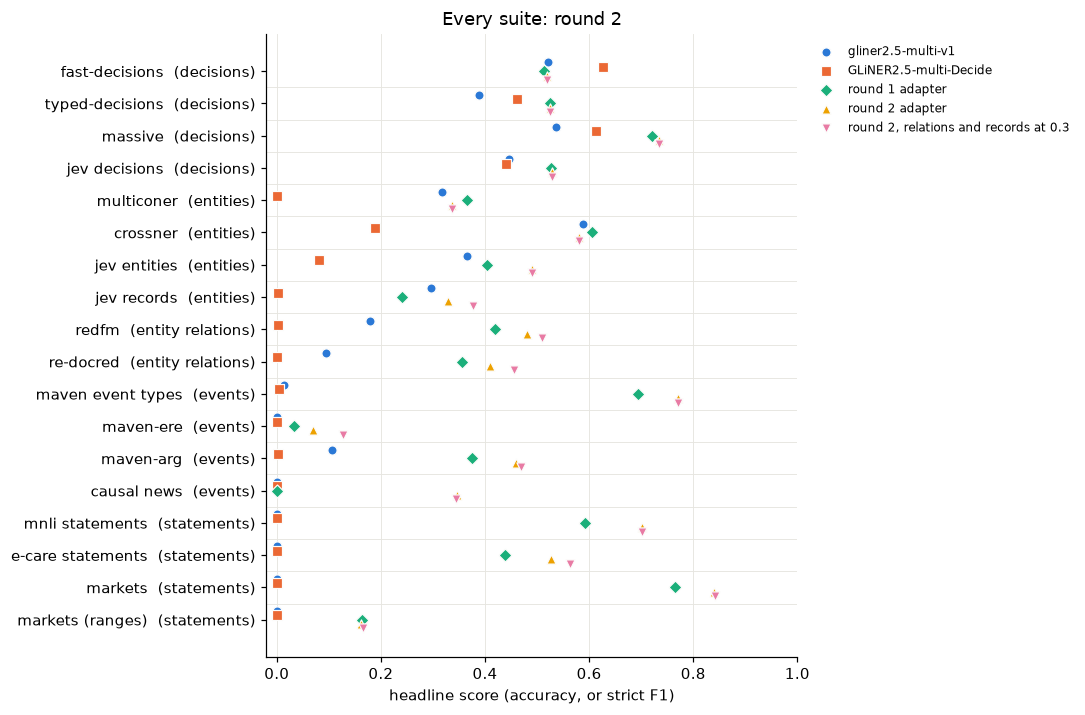

In [ ]:
dots(both, "Every suite: round 2")

- **Long spans learned.** The Causal News clauses go from nothing to 0.35 (0.45 when a clause one word off counts), jev's records from 0.24 to 0.33 (0.38 at the lower threshold, above the base's 0.30), MAVEN-Arg's event arguments from 0.38 to 0.46, its event types from 0.69 to 0.77.
- **Relations rise everywhere.** Between entities, RED^FM 0.42 to 0.48 and Re-DocRED 0.36 to 0.41 (0.51 and 0.46 at 0.3); between statements, MultiNLI 0.59 to 0.70, e-CARE 0.44 to 0.53 (0.56 at 0.3), the market lists 0.77 to 0.84.
- **Event relations, better and still weak.** MAVEN-ERE rises from 0.03 to 0.07, 0.13 at 0.3, where what the model reports is right 38% of the time and it finds 8% of the gold: 0.14 for relations in time, 0.11 for causes and preconditions, 0.13 for two mentions of one event, almost nothing for subevents.
- **Decisions hold.** MASSIVE 0.73, jev 0.53, typed decisions 0.52, as in round 1. fast-decisions stays at 0.52: CLINC and Banking77 did not bring the operational questions it asks.
- **Entities slip a little.** MultiCoNER 0.37 to 0.34 and CrossNER 0.61 to 0.58, both within the intervals, both the same way: still above and about at the base's.
- **A kind of market never seen stays hard.** Ranges: 0.16, as in round 1. The new kinds were not enough to teach ranges' logic.

## Dependency graphs over many markets

`statement_graph` relates any number of statements by reading them a few at a time ([GLiNER multitask](../33_gliner_multitask.ipynb#a-dependency-graph-over-many-statements)), and `market_pool` draws pools of market questions whose every relation is known. Both evaluation jobs read the same 20 pools of about 45 questions, test names only, the five kinds of round 1 plus ranges, in blocks of 8:

In [ ]:
g1, g2 = json.loads((ev / "graph.json").read_text()), json.loads((ev2 / "graph.json").read_text())
print(f"{g2['pools']} pools, {g2['questions']:,} questions, {g2['relations']:,} relations among them")
gnames = {"gliner2.5-multi-v1 (base)": "gliner2.5-multi-v1", "system-one-multi-full-balanced": "round 1, full, balanced", "system-one-multi-adapter-balanced": "round 1 adapter",
          "system-one-multi-full-sum": "round 1, full, summed", "system-one-multi-r2": "round 2 adapter"}
graphs = {gnames[m]: d for m, d in (g1["scores"] | g2["scores"]).items()}
pd.DataFrame({m: {f"F1 at {th.split()[-1]}": d[th]["all"]["f1"] for th in d} | {f"{r} (0.5)": d["threshold 0.5"].get(r, {}).get("f1", np.nan)
                                                                                  for r in ("implies", "rules out", "is a precondition of")}
              for m, d in graphs.items()}).T.style.format("{:.3f}").background_gradient(cmap="Blues", axis=0, vmin=0, vmax=1)

20 pools, 996 questions, 1,953 relations among them


,F1 at 0.3,F1 at 0.5,F1 at 0.7,implies (0.5),rules out (0.5),is a precondition of (0.5)
gliner2.5-multi-v1,0.000,0.000,0.000,0.000,0.000,0.000
"round 1, full, balanced",0.481,0.521,0.520,0.527,0.501,0.788
round 1 adapter,0.499,0.537,0.555,0.543,0.514,0.831
"round 1, full, summed",0.233,0.290,0.333,0.220,0.309,0.798
round 2 adapter,0.580,0.597,0.609,0.656,0.550,0.807


The round-2 adapter's graphs reach 0.60 F1 at 0.5 and 0.61 at 0.7 (round 1's adapter 0.54 and 0.56; the base finds nothing). Preconditions, reaching a round before winning, it marks with 0.81 F1; *implies* and *rules out* are harder, chains of thresholds and candidates where one missed link loses every relation that follows from it. Here is one pool, read with the round-2 adapter on this laptop's CPU (the published repo's revision `86a8ff8`; later versions follow):

In [ ]:
from gliner2 import AutoExtractor
from peft import PeftModel
from sysone.multitask import market_pool, statement_graph, graph_scores, cover
model = PeftModel.from_pretrained(AutoExtractor.from_pretrained("fastino/gliner2.5-multi-v1"), "sgaseretto/system-one-multi",
                                  revision="86a8ff8").get_base_model().eval()          # round 2, as first published
qs, gold = market_pool(15, seed=0, kinds=("thresholds", "deadlines", "matches", "elections", "stages", "ranges"))
edges = statement_graph(model, qs, block=8, threshold=0.5)
print(f"{len(qs)} questions read as {len(cover(len(qs), 8))} lists; {len(gold)} relations hold among them, the model marks {len(edges)}")
right = set(gold)
for h, t, r, c in edges[:12]: print("✓" if (h, t, r) in right else "✗", f"{qs[h][:62]:62} → {r:21} → {qs[t][:62]}")
{k: round(v, 3) for k, v in graph_scores(edges, gold)["all"].items()}

54 questions read as 21 lists; 113 relations hold among them, the model marks 187
✓ Will Brent crude oil trade below $70 on March 31, 2026?        → rules out             → Will Brent crude oil trade above $100 on March 31, 2026?
✓ Will Brent crude oil trade below $70 on March 31, 2026?        → rules out             → Will Brent crude oil trade above $90 on March 31, 2026?
✓ Will Bitcoin trade below $60,000 on March 31, 2025?            → rules out             → Will Bitcoin trade above $80,000 on March 31, 2025?
✓ Will the S&P 500 trade below 5,400 on March 31, 2025?          → rules out             → Will the S&P 500 trade above 5,800 on March 31, 2025?
✓ Will Brent crude oil trade above $100 on March 31, 2026?       → rules out             → Will Brent crude oil trade below $70 on March 31, 2026?
✓ Will Brent crude oil trade above $100 on March 31, 2026?       → rules out             → Will Brent crude oil trade below $90 on March 31, 2026?
✓ Will Brent crude oil trade below $90 on

{'p': 0.54, 'r': 0.894, 'f1': 0.673, 'edges': 187, 'gold': 113}

On this pool it finds nearly nine in ten of the relations that hold (89%) and marks too many: 86 of its 187 are wrong. Most of those (69) join questions about different things that share a form, as if "the S&P 500 below 5,400" implied "Bitcoin below $70,000"; another 17 join one asset on different dates. The model has learned the logic of a kind of question better than to check that two questions are about the same thing, and the training lists hardly asked it to: a list held at most one group of each kind, so it rarely had to tell two sets of price questions apart by their asset. Reading each pair in several lists and keeping its highest confidence adds such mistakes, which is why a stricter threshold helps the graphs a little.

## Round 3: dependencies between markets

The graph above relates questions of one form about different things, and every market relation it learned came from questions of our own making. Round 3 brings in questions people wrote, with relations fixed by how they were made or how they settle ([Market data](../34_market_data.ipynb)):

- **Paleka et al.'s forecasting questions** ([2024](https://arxiv.org/abs/2412.18544)): real questions from Metaculus and Manifold, others from the news and about 2028, each with questions an LLM wrote from it and a second call checked: its negation (they rule each other out), a paraphrase (they imply each other), a consequence (it implies it), and "and" and "or" with another question.
- **The exchanges' own rules.** On Kalshi, an event marked mutually exclusive, and on Polymarket a "neg-risk" event, resolve at most one market yes, so each rules out the rest; so do Manifold's multiple-choice markets whose answers sum to one. Kalshi markets that settle on a number (a temperature, a vote count) form ladders whose implications follow from their bounds, and so do Polymarket events whose questions differ in one number or one date.
- **A generator that reasons from outcomes.** Each market group lists what can happen; a question implies another when every outcome that makes it true makes the other true. Its lists put several groups of one kind together (gold and XRP, each with its thresholds), negate questions, and join them with "and" and "or".

None of these say how markets of different events relate, so a list never joins two events that share a name or a base question: every pair in it is related as its group says, or unrelated. Test lists come from base questions and events held out of training. The data job runs on a Kaggle CPU in 13 minutes, fetching the exchanges' public APIs, and stores the result as round 3 of the mix:

In [ ]:
#| eval: false
mk_job = remote(JOBS / "gold_markets.py", on="kaggle", hw="cpu", packages=["gliner2==2.1.0"], max_hours=3, checkpoints=False,
                data={"data": "kaggle:sgaseretto/system-one-multi-gold"}, name="gold-markets-2")
mk_job.wait()
built = Path(mk_job.fetch()) / "export"
gold_data_card(built, GOLD, title="System-One Multi gold mix", built_by="`gold_prepare.py`, `gold_update.py`, `gold_markets.py`")
push_data(built, GOLD, private=True); kaggle_dataset(built, GOLD)            # tagged round-3

In [ ]:
MARKETS = "gold-markets-2"                                   # the Kaggle job that built round 3
mk = Path(get_job(MARKETS).fetch()) / "export"
d3 = json.loads((mk / "data.json").read_text())["round_3"]
print("fetched:", d3["events"], "· groups:", d3["exchange_groups"], "· Paleka groups:", d3["paleka_groups"])
rows3 = read_jsonl(mk / "eval" / "rows.jsonl")
for suite in ("real markets", "paleka"):
    r = next(r for r in rows3 if r.get("suite") == suite and len(r["text"]) < 500)
    print(f"--- {suite}:\n{r['text']}")
    for k, v in r["gold"]["relations"].items():
        for h, t in v[:4]: print(f"    {h['text'][:58]} → {k} → {t['text'][:58]}")

fetched: {'kalshi': 8000, 'polymarket': 3600, 'manifold': 1100} · groups: {'kalshi ladder': 2582, 'kalshi exclusive': 1592, 'polymarket exclusive': 1334, 'manifold exclusive': 664, 'polymarket ladder': 405} · Paleka groups: 11475
--- real markets:
1. Will the margin of victory for Democrats in the Colorado's 5th District House election be at least 1 percentage points?
2. Will the margin of victory for Democrats in the Colorado's 5th District House election be at least 8 percentage points?
3. Will the margin of victory for Democrats in the Colorado's 5th District House election be at least 2 percentage points?
4. Will the margin of victory for Democrats in the Colorado's 5th District House election be at least 5 percentage points?
    Will the margin of victory for Democrats in the Colorado's → implies → Will the margin of victory for Democrats in the Colorado's
    Will the margin of victory for Democrats in the Colorado's → implies → Will the margin of victory for Democrats in the Col

From 12,700 events the exchanges give 6,577 groups, nearly two in three of them Kalshi's; Paleka et al.'s tuples give 11,475. Every list question that a test list also asks stays out of training (2,297 lists), and so do 1,836 near duplicates of test text. Four suites join the 18: 1,268 lists of Paleka et al.'s questions, 391 of real markets, and 550 from the new generator, 150 of them ranges, still a kind it never trains on.

## Round 3: training

The round-2 adapter goes on training (`init`), two epochs over the market records (`FOCUS`, 14,962 of them) and 45,000 records drawn from the rest of the mix (`REPLAY`), so that what it already does is kept in practice. The learning rates are half of round 2's, as for a model that is already most of the way:

In [ ]:
#| eval: false
r3_job = remote(JOBS / "gold_train.py", on="modal", hw="l40s", packages=["gliner2==2.1.0"], max_hours=1.5, cpu=4, memory_gb=16, budget=20, name="gold-multi-r3",
                data={"data": "hf:sgaseretto/system-one-multi-gold@round-3", "init": "modal:sysone-jobs/gold-multi-r2/outputs/export"},
                env={"EPOCHS": "2", "BALANCE": "1", "LORA_LR": "1e-4", "HEAD_LR": "5e-5", "RELATION_WEIGHT": "2", "SPAN_WEIGHT": "3",
                     "FOCUS": "Paleka,real markets,market lists v2", "REPLAY": "45000", "NAME": "system-one-multi-r3"})
r3_job.wait()
eval_r3 = remote(JOBS / "gold_evaluate.py", on="kaggle", hw="t4", packages=["gliner2==2.1.0"], max_hours=5, checkpoints=False, name="gold-evaluate-r3",
                 data={"eval": "kaggle:sgaseretto/system-one-multi-gold", "model": Path(r3_job.fetch()) / "export" / "system-one-multi-r3",
                       "model_2": "kaggle:sgaseretto/sysone-system-one-multi-r2-b080d3"},
                 env={"SETTINGS": "default;relations=0.3,structures=0.3", "ALSO_BASE": "1"})      # the base again, on the new suites
eval_r3.wait()

In [ ]:
EVAL3 = "gold-evaluate-r3"                                   # the Kaggle job that scored round 3 (and round 2 again)
ev3 = Path(get_job(EVAL3).fetch()) / "export"
r3 = json.loads((ev3 / "training-system-one-multi-r3.json").read_text())
v = [r3["before_training"]] + [x for x in r3["training"]["log"] if "valid_decision" in x]
print(f"{r3['training']['train']:,} records, {r3['training']['steps']:,} steps in {r3['training']['seconds'] / 60:.0f} minutes on Modal")
pd.DataFrame([{f"{h} loss": x[f"valid_{h}"] for h in HEADS} for x in v], index=["round 2 (before)", "after epoch 1", "after epoch 2"]).style.format("{:.3f}")

59,962 records, 8,509 steps in 27 minutes on Modal


,decision loss,relation loss,span loss
round 2 (before),0.454,0.480,1107.881
after epoch 1,0.433,0.363,398.364
after epoch 2,0.451,0.606,395.555


It cost about $1.60, bringing the month to $14.85 of the $20. The validation set gained the market records, so the first row is the round-2 adapter on it. The relation loss falls in the first epoch (0.48 to 0.36) and rises past its start in the second (0.61), as in round 2 but more. The adapter grows sure of what it marks, and a confident mistake costs a lot of loss. The test suites, again, say what that is worth.

## Round 3: scores

Four new suites join the headline, and the base is scored on them too (it finds nothing):

In [ ]:
HEADLINE += [("markets", "paleka", "relations_f1"), ("markets", "real markets", "relations_f1"),
             ("markets", "markets v2", "relations_f1"), ("markets", "markets v2 (ranges)", "relations_f1")]
s3 = json.loads((ev3 / "scores.json").read_text())
three = {"gliner2.5-multi-v1": start["gliner2.5-multi-v1 (base)"] | s3["gliner2.5-multi-v1 (base)"], "GLiNER2.5-multi-Decide": start["GLiNER2.5-multi-Decide"],
         "round 2 adapter": s3["system-one-multi-r2"], "round 3 adapter": s3["system-one-multi-r3"],
         "round 3, relations and records at 0.3": s3["system-one-multi-r3 (relations=0.3,structures=0.3)"]}
headline(three).T.style.format("{:.3f}").background_gradient(cmap="Blues", axis=1, vmin=0, vmax=1)

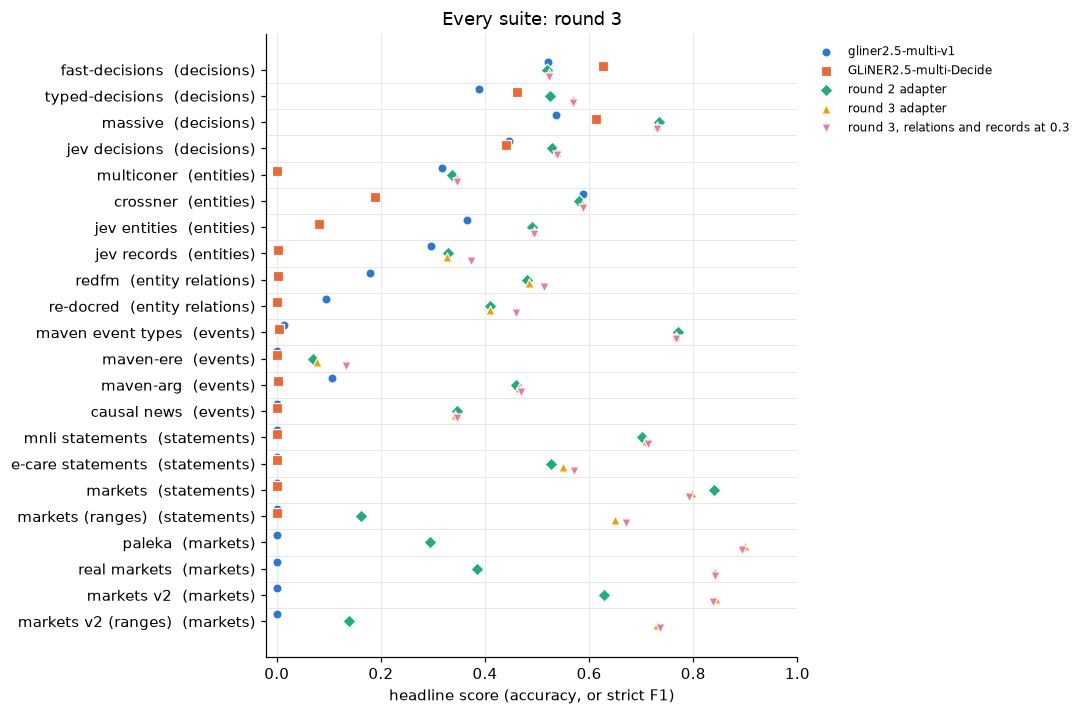

In [ ]:
dots(three, "Every suite: round 3")

- **Market questions people wrote.** Paleka et al.'s held-out questions go from 0.29 to 0.90, real markets from 0.38 to 0.84.
- **Generated lists with several groups of a kind.** From 0.63 to 0.84 (the new generator's test lists).
- **Ranges improve too.** The kind no generated training list holds goes from 0.16 to 0.65 (0.73 on the new generator's ranges), most likely from Kalshi's ladders, which hold ranges of their own (a temperature between 70 and 71°F) with the same logic of bounds.
- **Everything else holds.** Decisions, entities, entity and event relations are within a point of round 2, or above it: typed decisions 0.52 to 0.57, e-CARE 0.53 to 0.55.
- **One slip: round 1's market lists,** 0.84 to 0.80, mostly the test's own fault, as the next section shows.

How often is it right, and how much does it find?

In [ ]:
msuites = ["paleka", "real markets", "markets v2", "markets v2 (ranges)", "markets", "markets (ranges)"]
pd.DataFrame({(m, k): {s: s3[name][s][f"relations_{k}"] for s in msuites} for m, name in (("round 2", "system-one-multi-r2"), ("round 3", "system-one-multi-r3"))
              for k in ("p", "r", "f1")}).style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1)

On the questions people wrote, round 3 is right 96% and 97% of the time when it marks a relation, and finds 84% (Paleka) and 75% (real markets) of the gold. Round 2 was right 40% of the time on Paleka's questions; on real markets it was already right 82% of the time, but found only a quarter.

## Round 1's election lists, fixed

Many of round 3's "mistakes" on round 1's lists were elections: "Gabriel Attal wins the 2027 French presidential election" marked as ruling out "the Place Publique candidate wins it". It does, since Attal runs for Renaissance. Round 1's generator marked a candidate's win as implying their party's, and left out that it rules out every other party's; round 3 learned the rule from the new generator, which reasons from outcomes. The old generator now marks it too ([GLiNER multitask](../33_gliner_multitask.ipynb)), and makes the same 300 test lists again, word for word, with the relations they lacked:

In [ ]:
from sysone.multitask import market_rows, fits, gold_scores, relation_families
R1 = ("thresholds", "deadlines", "matches", "elections", "stages")       # round 1's kinds, for the lists and their unrelated questions
fixed = {r["id"]: r for r in market_rows(300, seed=13, part="test", kinds=R1, fillers=R1, suite="markets") if fits(r)}
stored = {r["id"]: r for r in rows3 if r.get("suite") == "markets"}
assert all(fixed[i]["text"] == r["text"] for i, r in stored.items())
npairs = lambda r: sum(len(v) for v in r["gold"]["relations"].values())
print(f"{sum(npairs(fixed[i]) - npairs(r) for i, r in stored.items())} relations added to {sum(npairs(fixed[i]) > npairs(r) for i, r in stored.items())} of the "
      f"{len(stored)} lists, which held {sum(map(npairs, stored.values())):,}")

148 relations added to 48 of the 300 lists, which held 2,621


Every evaluation job kept each model's answers, so the models are scored again without running them:

In [ ]:
def markets_f1(rows, answers_file) -> dict:
    "Strict F1 on round 1's market lists from a model's stored answers (in the order of `rows`), with the gold as stored and as fixed"
    got, ix = read_jsonl(answers_file), [i for i, r in enumerate(rows) if r.get("suite") == "markets"]
    f1 = lambda gold: gold_scores([got[i] for i in ix], gold, families=relation_families(), boot=0)["markets"]["relations_f1"]
    return {"as stored": f1([rows[i] for i in ix]), "fixed": f1([fixed[rows[i]["id"]] for i in ix])}
rows1 = read_jsonl(prep / "eval" / "rows.jsonl")                        # the test rows of rounds 1 and 2
pd.DataFrame({"round 1, full, balanced": markets_f1(rows1, ev / "answers-system-one-multi-full-balanced.jsonl"),
              "round 1 adapter": markets_f1(rows1, ev / "answers-system-one-multi-adapter-balanced.jsonl"),
              "round 1, full, summed": markets_f1(rows1, ev / "answers-system-one-multi-full-sum.jsonl"),
              "round 2 adapter": markets_f1(rows3, ev3 / "answers-system-one-multi-r2.jsonl"),
              "round 3 adapter": markets_f1(rows3, ev3 / "answers-system-one-multi-r3.jsonl")}).T.style.format("{:.3f}")

,as stored,fixed
"round 1, full, balanced",0.741,0.728
round 1 adapter,0.766,0.750
"round 1, full, summed",0.625,0.617
round 2 adapter,0.840,0.822
round 3 adapter,0.797,0.803


With the fixed gold, round 2 scores 0.82 and round 3 0.80: two points apart, not four. Every earlier model loses a little, having marked the rule less often. What is left of the slip is real: which party a test candidate runs for is not in the text, and round 3 guesses it wrong more often.

The graph pools come from the same generator. A Kaggle job reads them again with every model (`STAGES` skips the test suites and the timing), now keeping each edge, so a later fix to the gold needs no model run:

In [ ]:
#| eval: false
graphs_job = remote(JOBS / "gold_evaluate.py", on="kaggle", hw="t4", packages=["gliner2==2.1.0"], max_hours=2, checkpoints=False, name="gold-graphs-fixed",
                    data={"eval": "kaggle:sgaseretto/system-one-multi-gold"} | models | {"model_4": "kaggle:sgaseretto/sysone-system-one-multi-r2-b080d3",
                                                                                         "model_5": "kaggle:sgaseretto/sysone-system-one-multi-r3-f2e5ef"},
                    env={"STAGES": "graphs"})
graphs_job.wait()

In [ ]:
GRAPHS = "gold-graphs-fixed"                                 # the Kaggle job that read round 1's pools again, with the fixed gold
gf = json.loads((Path(get_job(GRAPHS).fetch()) / "export" / "graph.json").read_text())
stored_graphs = json.loads((ev / "graph.json").read_text())["scores"] | json.loads((ev3 / "graph.json").read_text())["scores"]
gnames |= {"system-one-multi-r3": "round 3 adapter"}
pd.DataFrame({gnames[m]: {"F1 at 0.5, as stored": stored_graphs[m]["threshold 0.5"]["all"]["f1"], "F1 at 0.5, fixed": d["threshold 0.5"]["all"]["f1"],
                          "F1 at 0.7, fixed": d["threshold 0.7"]["all"]["f1"]} for m, d in gf["scores"].items()}).T.style.format("{:.3f}")

,"F1 at 0.5, as stored","F1 at 0.5, fixed","F1 at 0.7, fixed"
gliner2.5-multi-v1,0.000,0.000,0.000
"round 1, full, balanced",0.521,0.524,0.520
round 1 adapter,0.537,0.537,0.554
"round 1, full, summed",0.290,0.294,0.335
round 2 adapter,0.597,0.597,0.608
round 3 adapter,0.787,0.796,0.804


The pools hold 50 relations more (2,003). In the graphs the gap mattered less, since elections are a small part of each pool: round 3 gains a point (0.79 to 0.80 at 0.5), the other models less than half of one.

## Round 3: graphs

The same 20 pools of round 1's kinds (with the fixed gold), now with two more sets of 20: pools from the new generator, and pools of real questions (Paleka's and the exchanges'), up to 8 groups each, no two sharing a name, so every relation between groups is a mistake:

In [ ]:
gm = json.loads((ev3 / "graphs_more.json").read_text())
pools = {"round 1's kinds": {m: gf["scores"][m] for m in gm["scores"]}} | {p: {m: d[p] for m, d in gm["scores"].items()} for p in gm["pools"]}
pd.DataFrame({(p, f"F1 at {th.split()[-1]}"): {gnames[m]: d[th]["all"]["f1"] for m, d in ms.items()} for p, ms in pools.items() for th in ("threshold 0.5", "threshold 0.7")}
             ).style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1)

At 0.5, the graphs go from 0.60 to 0.80 on round 1's kinds, from 0.52 to 0.80 on the new generator's, and from 0.59 to 0.85 on real questions. Here is the pool from before, read with round 3:

In [ ]:
model3 = PeftModel.from_pretrained(AutoExtractor.from_pretrained("fastino/gliner2.5-multi-v1"), "sgaseretto/system-one-multi", revision="10e0abe").get_base_model().eval()
edges3 = statement_graph(model3, qs, block=8, threshold=0.5)
print(f"the model marks {len(edges3)} relations (round 2: {len(edges)}), {sum((h, t, r) not in right for h, t, r, c in edges3)} of them wrong")
for h, t, r in [(h, t, r) for h, t, r, c in edges3 if (h, t, r) not in right][:8]: print("✗", f"{qs[h][:62]:62} → {r:21} → {qs[t][:62]}")
{k: round(v, 3) for k, v in graph_scores(edges3, gold)["all"].items()}

the model marks 137 relations (round 2: 187), 37 of them wrong
✗ Will the S&P 500 trade above 5,400 on March 31, 2025?          → rules out             → Will the S&P 500 close below 5,400 on June 30, 2026?
✗ Will the S&P 500 close below 5,400 on June 30, 2026?           → rules out             → Will the S&P 500 trade above 5,400 on March 31, 2025?
✗ Will the S&P 500 trade above 5,600 on March 31, 2025?          → implies               → Will the S&P 500 close above 5,400 on June 30, 2026?
✗ Will the S&P 500 close below 5,400 on June 30, 2026?           → rules out             → Will the S&P 500 trade above 5,600 on March 31, 2025?
✗ Will the S&P 500 trade above 5,600 on March 31, 2025?          → rules out             → Will the S&P 500 close below 5,400 on June 30, 2026?
✗ Will Bitcoin trade above $80,000 on March 31, 2025?            → implies               → Will the S&P 500 trade above 5,000 on March 31, 2025?
✗ Will the Social Democratic Party candidate win the 2026 Brazil → rul

{'p': 0.73, 'r': 0.885, 'f1': 0.8, 'edges': 137, 'gold': 113}

It marks 137 relations, 37 of them wrong, against round 2's 86. Joining two different assets, round 2's commonest mistake, falls from 43 to 9. The same asset on different dates is now among the commonest (12 of the 37): the S&P 500 above 5,600 on March 31, 2025 does not say where it closes on June 30, 2026. As many join questions of different kinds (a game and a championship), and 4 give a candidate the wrong party.

## Speed

The evaluation jobs also time one row at a time on the CPU (4 threads), beside the base, each job on its own machine:

In [ ]:
pd.DataFrame({f"round {i} job": {gnames[k]: v for k, v in json.loads((e / "latency.json").read_text())["ms_per_row_cpu_4_threads"].items()}
              for i, e in ((1, ev), (2, ev2), (3, ev3))}).round(0)

,round 1 job,round 2 job,round 3 job
gliner2.5-multi-v1,331.0,361.0,382.0
"round 1, full, balanced",330.0,NaN,NaN
round 1 adapter,416.0,446.0,NaN
"round 1, full, summed",331.0,NaN,NaN
round 2 adapter,NaN,434.0,465.0
round 3 adapter,NaN,NaN,460.0


A full fine-tune runs at the base's speed: it is the same network with other weights. An unmerged adapter adds its low-rank products at every layer, 20 to 26% more time a row here. Merging it (PEFT's `merge_and_unload()`) gives a checkpoint as fast as the base, and is left for later.

## Publishing

The round-3 adapter goes to the Hub unmerged and private, with a card `model_card` writes from its training record and the scores above ([GLiNER multitask](../33_gliner_multitask.ipynb#saving-the-model)). It replaces round 2's in `sgaseretto/system-one-multi`; the repo's history keeps both earlier versions (round 2 is revision `86a8ff8`):

In [ ]:
#| eval: false
from sysone.multitask import push_model
COLS = {"fast-decisions": ("fast-decisions", "accuracy"), "MASSIVE": ("massive", "accuracy"), "jev decisions": ("jev decisions", "accuracy"),
        "MultiCoNER": ("multiconer", "entities_f1"), "CrossNER": ("crossner", "entities_f1"), "REDFM relations": ("redfm", "relations_f1"),
        "Re-DocRED relations": ("re-docred", "relations_f1"), "MAVEN events": ("maven event types", "entities_f1"),
        "MAVEN-ERE event relations": ("maven-ere", "relations_f1"), "Causal News": ("causal news", "relations_f1"),
        "MultiNLI implies / rules out": ("mnli statements", "relations_f1"), "e-CARE causes": ("e-care statements", "relations_f1"),
        "generated markets": ("markets v2", "relations_f1"), "Paleka et al. questions": ("paleka", "relations_f1"), "real markets": ("real markets", "relations_f1")}
row = lambda s: {c: (round(s[a][k], 3) if a in s else None) for c, (a, k) in COLS.items()}
push_model(Path(r3_job.fetch()) / "export" / "system-one-multi-r3", "sgaseretto/system-one-multi", private=True, replace=True,
           base="fastino/gliner2.5-multi-v1", data_repo=GOLD,
           scores={"gliner2.5-multi-v1 (base)": row(three["gliner2.5-multi-v1"]), "GLiNER2.5-multi-Decide": row(three["GLiNER2.5-multi-Decide"]),
                   "system-one-multi round 2 (the previous version)": row(s3["system-one-multi-r2 (relations=0.3,structures=0.3)"]),
                   "system-one-multi (this adapter)": row(three["round 3, relations and records at 0.3"])},
           scores_note="The base and GLiNER2.5-multi-Decide are read at GLiNER2's default threshold of 0.5; the adapters at 0.5 for entities and 0.3 for relations "
                       "and record fields. Market questions are held out by base question or by event. The training section below describes the second round.",
           description="[fastino/gliner2.5-multi-v1](https://huggingface.co/fastino/gliner2.5-multi-v1) trained further on gold labels from public datasets, as a LoRA adapter, "
                       "to make decisions of every kind, find entities of any type, and relate them: entity to entity, event to event (causes, is a precondition of, "
                       "happens before, has subevent), and statement to statement (implies, rules out), including the questions of prediction markets. "
                       "It was trained in two rounds of two epochs each: the first on the mix as tagged `round-2` in its data repo, the second on market questions "
                       "(Paleka et al.'s forecasting questions, exclusive groups and numeric ladders from Kalshi, Polymarket and Manifold, and generated questions) "
                       "with 45,000 records of the rest replayed. Trained with [sysonelib](https://github.com/sgaseretto/sysonelib)'s `sysone.multitask`.",
           limitations=["Relations between events stay weak: 0.13 F1 on MAVEN-ERE (right 37% of the time, finding 8% of the gold pairs), and subevents almost never.",
                        "No gain on fast-decisions (0.52, as the base; GLiNER2.5-multi-Decide 0.63): operational questions such as routing a ticket or triaging an email are scarce in the training data.",
                        "The real-market tests hold relations within one event (outcomes that rule each other out, ladders of thresholds or dates), which the exchanges' rules fix; "
                        "dependencies between different events are unlabelled anywhere and untested. Paleka et al.'s relations were written and checked by an LLM.",
                        "When it marks a market relation it is usually right (precision 0.95 on Paleka's questions, 0.96 on real markets), but it misses some (recall 0.84 and 0.75).",
                        "Plain entity typing is about the base's (CrossNER 0.59 against 0.59, MultiCoNER 0.35 against 0.32).",
                        "Trained and tested in English only; the base is multilingual, and other languages are untested.",
                        "The thresholds of 0.3 for relations and records were picked from a sweep on the same test suites.",
                        "Unmerged, it is about 20% slower than the base on a CPU (460 against 382 ms a row, 4 threads)."])

It loads over the base with `peft`, and answers like any GLiNER2 model:

```python
from gliner2 import AutoExtractor
from peft import PeftModel

model = PeftModel.from_pretrained(AutoExtractor.from_pretrained("fastino/gliner2.5-multi-v1"), "sgaseretto/system-one-multi").get_base_model()
model.classify_text("My card was charged twice", {"intent": ["billing", "shipping", "account"]})       # {'intent': 'billing'}
model.extract_relations("1. Will Bitcoin close above $100,000 on June 30?\n2. Will Bitcoin close above $90,000 on June 30?",
                        {"implies": "if the first is true, the second is true as well", "rules out": "the two cannot both be true"}, threshold=0.3)
# {'relation_extraction': {'implies': [('Will Bitcoin close above $100,000 on June 30', 'Will Bitcoin close above $90,000 on June 30')], 'rules out': []}}
```

`revision="86a8ff8"` in `from_pretrained` loads round 2 instead.

## What next

- **Merging**, when the adapter's form is no longer needed: `merge_and_unload()` gives a plain checkpoint, as fast as the base.
- **Dependencies between events on real markets.** Every real-market relation tested here is one the exchange's rules fix within an event. Whether a Fed decision bears on a recession market is labelled nowhere; a few hundred such pairs, labelled by hand, would say how far the model carries.
- **The same thing on another date.** The graphs' commonest mistake now: a list that holds one asset's ladders on two dates would teach it.
- **Relations between events.** Still the weakest skill (0.13 on MAVEN-ERE). More epochs over its rows, shorter windows, and thresholds of their own are the next things to try; subevents need more examples than MAVEN-ERE has.
- **Operational decisions.** fast-decisions asks the kind of question the mix barely has (routing, triage, handoff, policy). Data shaped like those tasks is what is missing.